# THYMS Colombia — Pronóstico de demanda y gemelo digital de la planta



**Para correrlo:** el archivo `Datos Thyms Completo.xlsx` debe estar en la misma carpeta. Todos
los supuestos están en la celda *Configuración*.

## 1. Configuración y datos

In [1]:
import math
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import openpyxl
import simpy                 # si falta: pip install simpy

In [2]:
# ---------------- Configuración (supuestos editables) ----------------
ARCHIVO = "Datos Thyms Completo.xlsx"

PRECIO_UND = 12_900          # COP por tubo; el valor que se usó en el Corte 1 para pasar de pesos a unidades
INDICE_SUPUESTO = {9: 1.0, 10: 1.0, 11: 1.0, 12: 1.0}   # índice estacional de los meses SIN datos (sep-dic)
CV_CHOQUE_MENSUAL = 0.10     # variación mensual de la demanda que el pronóstico no explica (supuesto)

INICIO = dt.date(2026, 9, 1) # primer mes sin datos reales
MESES = 12

SUBLOTE = 600                # tubos que pasan juntos de llenado a encartonado y empaque (25 cajas master)
KG_LOTE = 500                # kg de base y colorantes por lote
CV_MTTR = 0.5                # dispersión del tiempo de reparación; el libro solo da el promedio
SS_MP_DIAS = 15              # stock de seguridad de materia prima, días hábiles (hoja Restricciones)
REVISION_MP_DIAS = 5         # cada cuánto se revisa el pedido de materia prima

N_REP = 30                   # réplicas por escenario
SEMILLA = 2026

MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
PRODS = ["A", "B", "C"]
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "gris": "#898781"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

def es(x, d=0):
    """Número con formato en español: 1.234.567,8"""
    return f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def tabla(df, dec=0):
    """La misma tabla con los números en formato español (dec: decimales, o dict por columna)."""
    out = df.copy()
    for col in out.select_dtypes("number").columns:
        d = dec.get(col, 0) if isinstance(dec, dict) else dec
        out[col] = out[col].map(lambda v, d=d: es(v, d))
    return out

Del libro solo se leen **datos de entrada**; lo que allí es fórmula se calcula aquí.

In [3]:
def cargar_datos(ruta):
    wb = openpyxl.load_workbook(ruta)
    v = lambda hoja, ref: wb[hoja][ref].value
    assert str(v("Productos", "L4")).startswith("Punto de reorden"), "Cambió la hoja Productos"

    D = {"par": dict(dias_mes=v("Parámetros", "B4"), turnos=v("Parámetros", "B5"), horas_turno=v("Parámetros", "B6"),
                     tubos_lote=v("Parámetros", "B9"), und_caja=v("Parámetros", "B10"))}
    D["prod"] = pd.DataFrame([dict(p=v("Productos", f"A{r}")[0], nombre=v("Productos", f"A{r}")[3:],
                                   demanda=v("Productos", f"C{r}"), rend=v("Productos", f"E{r}"),
                                   stock=v("Productos", f"I{r}"), bodega=v("Productos", f"K{r}"),
                                   rop=v("Productos", f"L{r}"), lote=v("Productos", f"M{r}"),
                                   wip=v("Productos", f"N{r}"), mp_kg=v("Productos", f"O{r}"))
                              for r in (5, 6, 7)]).set_index("p")
    D["mp"] = dict(stock_kg=float(D["prod"].mp_kg.sum()), lead_time=v("Productos", "E12"))

    T = pd.DataFrame([dict(estacion=v("Tiempos", f"A{r}"), p=v("Tiempos", f"B{r}"), unidad=v("Tiempos", f"C{r}"),
                           prom=v("Tiempos", f"D{r}"), desv=v("Tiempos", f"E{r}"), rango=v("Tiempos", f"I{r}"))
                      for r in range(5, 23)])
    T["minimo"], T["maximo"] = T.prom * (1 - T.rango), T.prom * (1 + T.rango)
    D["tiempos"] = T.set_index(["estacion", "p"])

    D["oee"] = pd.Series({v("Utilizacion", f"A{r}"): v("Utilizacion", f"E{r}") for r in range(5, 11)})
    D["alist"] = pd.DataFrame({equipo: [v("Alistamiento", f"{col}{r}") for r in (5, 6, 7)]
                               for equipo, col in (("reactor", "B"), ("llenadora", "C"), ("encartonadora", "D"))},
                              index=["tono", "AC", "B"])                                    # minutos
    D["fallas"] = pd.DataFrame({"mtbf": [v("Fallas", f"B{r}") for r in range(5, 10)],
                                "mttr": [v("Fallas", f"C{r}") for r in range(5, 10)]},
                               index=[v("Fallas", f"A{r}") for r in range(5, 10)])
    D["ventas"] = np.array([v("Ventas", f"B{r}") for r in range(5, 13)], dtype=float)       # COP, ene-ago 2026
    ws, r, cop = wb["Facturas Mayo-Julio"], 5, []
    while ws[f"A{r}"].value is not None:
        cop.append(float(ws[f"E{r}"].value)); r += 1
    D["facturas"] = np.array(cop)                                                           # COP por pedido
    return D

D = cargar_datos(ARCHIVO)
prod, par = D["prod"], D["par"]
prod[["nombre", "demanda", "rend", "stock", "bodega", "rop", "lote"]]

,nombre,demanda,rend,stock,bodega,rop,lote
p,,,,,,,
A,Kolorezza permanente 60 g,48000,0.985,14000,26000,8000,15600
B,Visalia sin amoníaco 60 g,30000,0.975,8500,18000,5500,7800
C,Thym's Coloring permanente 60 g,22000,0.988,7000,14000,4500,15600


In [4]:
y = D["ventas"]                            # COP por mes, ene-ago 2026
DEMANDA_PLANTA = float(prod.demanda.sum()) # tubos por mes en el libro
ESCALA = DEMANDA_PLANTA / (y.mean() / PRECIO_UND)
print(f"Venta real promedio: {es(y.mean())} COP/mes = {es(y.mean()/PRECIO_UND)} tubos/mes "
      f"-> equivale al {es(100/ESCALA, 1)} % de la planta ({es(DEMANDA_PLANTA)} tubos/mes)")

Venta real promedio: 150.997.582 COP/mes = 11.705 tubos/mes -> equivale al 11,7 % de la planta (100.000 tubos/mes)


## 2. Pronóstico de demanda

### 2.1 Revisión del pronóstico del Corte 1

Suavización exponencial simple con α = 0,05, arrancando en la venta de enero, sobre enero a julio.

In [5]:
def ses(serie, alpha, nivel0):
    """Suavización exponencial simple. Devuelve (pronósticos a un paso, pronóstico del mes siguiente)."""
    F, nivel = np.empty(len(serie)), nivel0
    for t, valor in enumerate(serie):
        F[t] = nivel
        nivel = alpha * valor + (1 - alpha) * nivel
    return F, nivel

def metricas(real, pron):
    e = np.asarray(real) - np.asarray(pron)
    mad = np.abs(e).mean()
    return dict(MAD=mad, RMSE=np.sqrt((e ** 2).mean()), MAPE=(np.abs(e) / real).mean(),
                sesgo=e.mean(), senal_rastreo=e.sum() / mad)

F_c1, pron_ago_c1 = ses(y[:7], 0.05, y[0])
m_c1 = metricas(y[1:7], F_c1[1:])          # igual que en el Corte 1: febrero a julio
print(f"MAD = {es(m_c1['MAD'])} COP | MAPE = {es(100*m_c1['MAPE'], 1)} %")
print(f"Sesgo (error promedio) = {es(m_c1['sesgo'])} COP | Señal de rastreo = {es(m_c1['senal_rastreo'], 2)} (límite usual: ±4)")
print(f"Agosto: pronóstico {es(pron_ago_c1)} vs real {es(y[7])} COP")

MAD = 80.172.875 COP | MAPE = 53,4 %
Sesgo (error promedio) = 63.063.608 COP | Señal de rastreo = 4,72 (límite usual: ±4)
Agosto: pronóstico 114.671.388 vs real 119.882.540 COP


### 2.2 Elección del método

La serie no tiene tendencia significativa: se comporta como un nivel estable más variación. Los
métodos se comparan con **origen móvil**: con los primeros 3 meses se pronostica el 4.º, con los
primeros 4 el 5.º, y así hasta agosto.

In [6]:
tend = stats.linregress(np.arange(len(y)), y)
print(f"Tendencia: {es(tend.slope)} COP/mes, valor p = {es(tend.pvalue, 2)} (no significativa)")

def p_holt(alpha, beta):
    def f(h):
        nivel, tend = h[0], h[1] - h[0]
        for valor in h[1:]:
            nuevo = alpha * valor + (1 - alpha) * (nivel + tend)
            tend, nivel = beta * (nuevo - nivel) + (1 - beta) * tend, nuevo
        return nivel + tend
    return f
p_ses = lambda alpha: (lambda h: ses(h, alpha, h[:3].mean())[1])     # nivel inicial = promedio de 3 meses

def origen_movil(modelo, minimo=3):
    """Métricas de pronosticar cada mes solo con los meses anteriores."""
    return metricas(y[minimo:], np.array([modelo(y[:i]) for i in range(minimo, len(y))]))

ALPHA = float(min(np.round(np.arange(0.05, 1.0, 0.05), 2), key=lambda a: origen_movil(p_ses(a))["RMSE"]))
ELEGIDO = f"SES (α={es(ALPHA, 2)}; nivel inicial promedio)"
modelos = {"Ingenuo (último mes)": lambda h: h[-1],
           "Promedio histórico": lambda h: h.mean(),
           "Promedio móvil (3)": lambda h: h[-3:].mean(),
           "SES del Corte 1 (α=0,05; arranca en enero)": lambda h: ses(h, 0.05, h[0])[1],
           ELEGIDO: p_ses(ALPHA),
           "Holt (α=0,3; β=0,3)": p_holt(0.3, 0.3),
           "Regresión lineal": lambda h: np.polyval(np.polyfit(np.arange(len(h)), h, 1), len(h))}
cv = pd.DataFrame({nombre: origen_movil(f) for nombre, f in modelos.items()}).T.sort_values("RMSE")
vista = cv.assign(MAD=cv.MAD / 1e6, RMSE=cv.RMSE / 1e6, MAPE=cv.MAPE * 100, sesgo=cv.sesgo / 1e6)
tabla(vista.rename(columns={"MAD": "MAD (M COP)", "RMSE": "RMSE (M COP)", "MAPE": "MAPE (%)",
                            "sesgo": "Sesgo (M COP)", "senal_rastreo": "Señal de rastreo"}),
      {"MAD (M COP)": 1, "RMSE (M COP)": 1, "MAPE (%)": 1, "Sesgo (M COP)": 1, "Señal de rastreo": 2})

Tendencia: 6.741.938 COP/mes, valor p = 0,51 (no significativa)


,MAD (M COP),RMSE (M COP),MAPE (%),Sesgo (M COP),Señal de rastreo
"SES (α=0,05; nivel inicial promedio)","54,7","63,6","56,3","2,4","0,22"
Promedio histórico,"61,9","69,3","60,2","8,6","0,69"
Promedio móvil (3),"67,3","75,1","65,1","-1,9","-0,14"
"SES del Corte 1 (α=0,05; arranca en enero)","65,2","76,8","47,3","44,6","3,42"
Regresión lineal,"92,6","111,6","109,4","-31,8","-1,72"
Ingenuo (último mes),"104,0","111,9","101,5","-16,2","-0,78"
"Holt (α=0,3; β=0,3)","106,7","127,5","126,1","-106,7","-5,00"


Gana la **suavización exponencial simple con α bajo y nivel inicial igual al promedio de los
primeros meses**: el mismo método del Corte 1, corregido en el arranque. Tiene el menor RMSE y casi
no tiene sesgo; los métodos con tendencia y el ingenuo quedan muy por encima.

El MAPE del Corte 1 sale mejor porque el MAPE premia a los pronósticos bajos; para planear
producción pesa más el sesgo. Con α tan bajo el resultado es casi el promedio histórico, y el error
de un mes cualquiera es grande: por eso el pronóstico se entrega con intervalo.

### 2.3 Pronóstico a 12 meses con estacionalidad

Con un solo año incompleto no se puede validar un modelo estacional. El patrón observado se usa
como **escenario**: de enero a agosto, índice = venta del mes / promedio; de septiembre a
diciembre, el valor de `INDICE_SUPUESTO`. El pronóstico de un mes es `nivel × índice`.

In [7]:
NIVEL_COP = ses(y, ALPHA, y[:3].mean())[1]                 # nivel con los 8 meses
SIGMA_REL = cv.loc[ELEGIDO, "RMSE"] / NIVEL_COP            # error típico de un mes, medido fuera de muestra
NIVEL_PLANTA = NIVEL_COP / PRECIO_UND * ESCALA             # tubos de planta por mes
INDICES = {m: y[m - 1] / y.mean() for m in range(1, 9)} | INDICE_SUPUESTO
Z = stats.norm.ppf(0.90)                                   # intervalo del 80 %

def meses_desde(inicio, k):
    return [((inicio.year + (inicio.month - 1 + i) // 12), (inicio.month - 1 + i) % 12 + 1) for i in range(k)]

pron12 = pd.DataFrame([{"Mes": f"{MES[m-1]} {a}", "Índice": INDICES[m], "Pronóstico (und)": NIVEL_PLANTA * INDICES[m]}
                       for a, m in meses_desde(INICIO, MESES)])
pron12["Límite inferior"] = pron12["Pronóstico (und)"] * (1 - Z * SIGMA_REL)
pron12["Límite superior"] = pron12["Pronóstico (und)"] * (1 + Z * SIGMA_REL)
print(f"Nivel: {es(NIVEL_COP)} COP/mes = {es(NIVEL_PLANTA)} tubos/mes de planta | error típico de un mes: {es(100*SIGMA_REL)} %")
tabla(pron12, {"Índice": 2})

Nivel: 151.055.237 COP/mes = 100.038 tubos/mes de planta | error típico de un mes: 42 %


,Mes,Índice,Pronóstico (und),Límite inferior,Límite superior
0,Sep 2026,"1,00",100.038,46.038,154.038
1,Oct 2026,"1,00",100.038,46.038,154.038
2,Nov 2026,"1,00",100.038,46.038,154.038
3,Dic 2026,"1,00",100.038,46.038,154.038
4,Ene 2027,"0,63",63.437,29.194,97.681
5,Feb 2027,"1,02",101.928,46.908,156.949
6,Mar 2027,"1,33",133.168,61.285,205.052
7,Abr 2027,"0,35",34.747,15.991,53.503
8,May 2027,"1,31",130.836,60.212,201.461
9,Jun 2027,"1,04",103.737,47.740,159.733


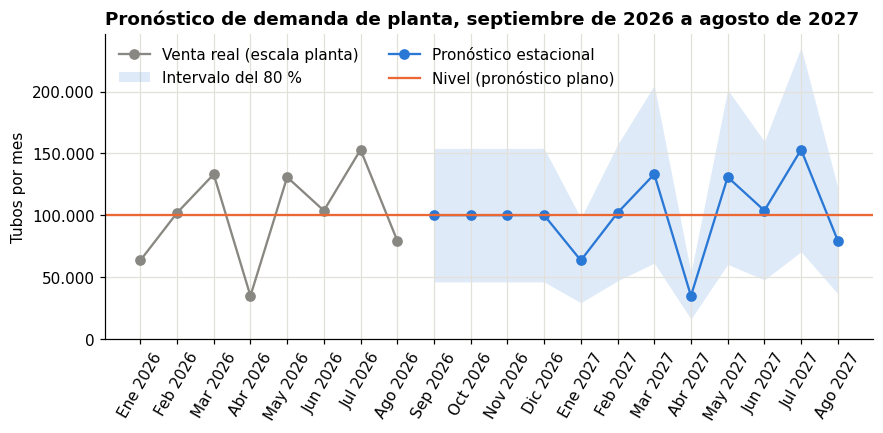

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot([f"{MES[m]} 2026" for m in range(8)], y / PRECIO_UND * ESCALA, marker="o", color=COLOR["gris"], label="Venta real (escala planta)")
ax.fill_between(pron12.Mes, pron12["Límite inferior"], pron12["Límite superior"], color=COLOR["A"], alpha=0.15, linewidth=0, label="Intervalo del 80 %")
ax.plot(pron12.Mes, pron12["Pronóstico (und)"], marker="o", color=COLOR["A"], label="Pronóstico estacional")
ax.axhline(NIVEL_PLANTA, color=COLOR["B"], linewidth=1.5, label="Nivel (pronóstico plano)")
ax.set_ylabel("Tubos por mes"); ax.set_ylim(0, None); ax.tick_params(axis="x", labelrotation=60)
ax.yaxis.set_major_formatter(lambda v, _: es(v)); ax.legend(ncols=2, loc="upper left")
ax.set_title("Pronóstico de demanda de planta, septiembre de 2026 a agosto de 2027")
plt.show()

### 2.4 El pronosticador que usa el gemelo

El gemelo consulta el pronóstico para planear y lo **actualiza cada mes** con la demanda que mide.
El tamaño de los pedidos sale de las facturas reales (lognormal).

In [9]:
class Pronosticador:
    """Suavización exponencial simple sobre la demanda desestacionalizada (tubos de planta por mes)."""

    def __init__(self, nivel, alpha, indices, peso_estacional=1.0):
        self.nivel, self.alpha, self.indices, self.peso = nivel, alpha, indices, peso_estacional

    def indice(self, mes):
        return 1 + self.peso * (self.indices[mes] - 1)

    def pronostico(self, mes):
        return self.nivel * self.indice(mes)

    def actualizar(self, mes, demanda_real):
        self.nivel = self.alpha * demanda_real / self.indice(mes) + (1 - self.alpha) * self.nivel

log_ped = np.log(D["facturas"])
PRON = dict(nivel_planta=NIVEL_PLANTA, alpha=ALPHA, indices=INDICES,
            mu_pedido=log_ped.mean(), sg_pedido=log_ped.std(ddof=1))
print(f"Pedido promedio: {es(D['facturas'].mean())} COP = {es(D['facturas'].mean()/PRECIO_UND)} tubos")

Pedido promedio: 1.273.304 COP = 99 tubos


## 3. Gemelo digital de la planta

### 3.1 Qué representa

```
Pedidos de clientes ──> Producto terminado (A, B, C) ──> despacho o pendiente
                             ▲                 │ revisión diaria: ¿posición ≤ punto de reorden?
                             │                 ▼
  Materia prima ──> Pesaje ──> Mezcla (2 reactores) ──> Control de calidad
  (500 kg/lote)                                                 │
       Empaque caja master <── Encartonado <── Llenado y sellado ┘   (por sublotes de 600 tubos)
```

| Elemento | Cómo se modela | Fuente |
|---|---|---|
| Demanda | Pedidos diarios: llegadas Poisson, tamaño lognormal; nivel mensual = base × índice estacional × choque aleatorio | Facturas reales y sección 2 |
| Tiempos de proceso | Normal truncada entre mínimo y máximo, por estación y producto | Hoja `Tiempos` |
| Fallas | Tiempo entre fallas exponencial (en horas de marcha), reparación lognormal | Hoja `Fallas` |
| Alistamientos | Cambio de tono, A↔C o A/C↔B en reactor, llenadora y encartonadora | Hoja `Alistamiento` |
| OEE | Las fallas explican una parte; el resto se aplica como pérdida de velocidad | Hojas `Utilizacion` y `Fallas` |
| Calidad | Rendimiento por producto, al final de la línea | Hoja `Productos` |
| Control de producción | Punto de reorden y lote por producto, revisión diaria | Hoja `Productos` |
| Materia prima | Revisión semanal; se pide hasta cubrir lead time + seguridad según el pronóstico | Hojas `Productos` y `Restricciones` |
| Calendario | Lunes a viernes sin festivos de Colombia; el reloj avanza solo en horas de turno | Hoja `Parámetros` |


In [10]:
def pascua(a):
    """Domingo de Pascua (algoritmo de Meeus)."""
    g, c, k = a % 19, a // 100, a % 100
    h = (19 * g + c - c // 4 - (c - (c + 8) // 25 + 1) // 3 + 15) % 30
    i = (32 + 2 * (c % 4) + 2 * (k // 4) - h - k % 4) % 7
    mes, dia = divmod(h + i - 7 * ((g + 11 * h + 22 * i) // 451) + 114, 31)
    return dt.date(a, mes, dia + 1)

def festivos_colombia(a):
    lunes = lambda d: d + dt.timedelta(days=(7 - d.weekday()) % 7)      # ley Emiliani
    p = pascua(a)
    fijos = [(1, 1), (5, 1), (7, 20), (8, 7), (12, 8), (12, 25)]
    trasladables = [(1, 6), (3, 19), (6, 29), (8, 15), (10, 12), (11, 1), (11, 11)]
    f = {dt.date(a, m, d) for m, d in fijos} | {lunes(dt.date(a, m, d)) for m, d in trasladables}
    return f | {p - dt.timedelta(3), p - dt.timedelta(2)} | {p + dt.timedelta(k) for k in (43, 64, 71)}

def dias_habiles(a, m):
    fest = festivos_colombia(a)
    ultimo = (dt.date(a + m // 12, m % 12 + 1, 1) - dt.timedelta(1)).day
    return [d for d in (dt.date(a, m, k) for k in range(1, ultimo + 1)) if d.weekday() < 5 and d not in fest]

### 3.2 El modelo

In [11]:
E_PES, E_MEZ, E_QC = "Pesaje", "Mezcla y emulsión", "Control de calidad de lote"
E_LLE, E_ENC, E_EMP = "Llenado y sellado", "Encartonado", "Empaque caja master"

CFG_BASE = dict(
    turnos=None,                    # None = los del libro
    factor_demanda=1.0,             # multiplica la demanda de planta
    peso_estacional_real=1.0,       # cuánta estacionalidad ocurre de verdad (0 = demanda plana)
    peso_estacional_pron=1.0,       # cuánta estacionalidad conoce el planeador
    cv_choque_mensual=CV_CHOQUE_MENSUAL,
    politica="rop_fijo",            # "rop_fijo" (libro) o "rop_pronostico" (se ajusta con el pronóstico)
    lote=None,                      # dict por producto para cambiar el lote del libro
    modelar_mp=True,
    sensores=False, dt_sensor=1.0)  # sensores: una lectura cada dt_sensor horas

def lognormal_media(rng, media, cv):
    s2 = math.log(1 + cv ** 2)
    return rng.lognormal(math.log(media) - s2 / 2, math.sqrt(s2))


class Maquina:
    """Equipo con estados (libre, marcha, alistamiento, falla) y fallas según horas de marcha."""

    def __init__(self, env, oee, rng, mtbf=None, mttr=None):
        self.env, self.rng, self.mtbf, self.mttr = env, rng, mtbf, mttr
        disponibilidad = mtbf / (mtbf + mttr) if mtbf else 1.0
        self.desempeno = oee / disponibilidad          # pérdida de velocidad que completa el OEE del libro
        self.vida = rng.exponential(mtbf) if mtbf else math.inf
        self.estado, self.t_cambio = "libre", 0.0
        self.horas = dict(libre=0.0, marcha=0.0, alistamiento=0.0, falla=0.0)
        self.ultimo_producto = self.ultimo_lote = None
        self.velocidad = 0.0

    def _pasar_a(self, estado):
        self.horas[self.estado] += self.env.now - self.t_cambio
        self.estado, self.t_cambio = estado, self.env.now

    def alistar(self, horas):
        if horas > 0:
            self._pasar_a("alistamiento")
            yield self.env.timeout(horas)
        self._pasar_a("libre")

    def operar(self, horas, velocidad=0.0):
        restante = horas
        while restante > 1e-12:
            tramo = min(restante, self.vida)
            self._pasar_a("marcha"); self.velocidad = velocidad
            yield self.env.timeout(tramo)
            restante -= tramo; self.vida -= tramo
            if self.vida <= 1e-12:                       # falla: se repara y el trabajo continúa
                self._pasar_a("falla"); self.velocidad = 0.0
                yield self.env.timeout(lognormal_media(self.rng, self.mttr, CV_MTTR))
                self.vida = self.rng.exponential(self.mtbf)
        self._pasar_a("libre"); self.velocidad = 0.0


class GemeloThyms:
    def __init__(self, D, PRON, cfg=None, semilla=1):
        c = self.c = {**CFG_BASE, **(cfg or {})}
        self.D, self.rng, self.rng_sensor = D, np.random.default_rng(semilla), np.random.default_rng(semilla + 10_000)
        env = self.env = simpy.Environment()
        par, prod = D["par"], D["prod"]

        # --- calendario: el reloj avanza en horas de turno ---
        self.H = (c["turnos"] or par["turnos"]) * par["horas_turno"]
        todos = meses_desde(INICIO, MESES + 4)                       # 4 meses extra para mirar hacia adelante
        self.habiles = {am: dias_habiles(*am) for am in todos}
        self.dias = [d for am in todos[:MESES] for d in self.habiles[am]]
        self.dias_ext = [d for am in todos for d in self.habiles[am]]
        self.T = len(self.dias) * self.H

        # --- política, pronóstico y datos del libro ---
        self.Q = {p: (c["lote"] or {}).get(p, prod.lote[p]) for p in PRODS}
        self.rop_base = prod.rop.to_dict()
        self.rop = dict(self.rop_base)
        self.pron = Pronosticador(PRON["nivel_planta"] * c["factor_demanda"], PRON["alpha"], PRON["indices"],
                                  c["peso_estacional_pron"])
        self.pedido_medio = math.exp(PRON["mu_pedido"] + PRON["sg_pedido"] ** 2 / 2) / PRECIO_UND   # tubos
        self.tiempos = {clave: (r.prom, r.desv, r.minimo, r.maximo) for clave, r in D["tiempos"].iterrows()}
        self.alist = {(tipo, equipo): D["alist"].loc[tipo, equipo] / 60 for tipo in D["alist"].index for equipo in D["alist"].columns}   # horas
        self.rend, self.dem_base = prod.rend.to_dict(), prod.demanda.to_dict()
        self.n_lote, self.und_caja = par["tubos_lote"], par["und_caja"]

        # --- equipos ---
        oee, fa = D["oee"], D["fallas"]
        nueva = lambda est, falla=None: Maquina(env, oee[est], self.rng, *(fa.loc[falla] if falla else (None, None)))
        self.maq = {"Pesaje": nueva(E_PES), "Control de calidad": nueva(E_QC),
                    "Reactor 1": nueva(E_MEZ, "Reactor 1"), "Reactor 2": nueva(E_MEZ, "Reactor 2"),
                    "Llenadora": nueva(E_LLE, "Llenadora de tubos"),
                    "Encartonadora": nueva(E_ENC, "Encartonadora"), "Empaque": nueva(E_EMP, "Línea de empaque")}
        self.res = {k: simpy.Resource(env, 1) for k in ("Pesaje", "Control de calidad", "Encartonadora", "Empaque")}
        self.res_llenadora = simpy.PriorityResource(env, 1)
        self.reactores = simpy.Store(env)
        self.reactores.items = [self.maq["Reactor 1"], self.maq["Reactor 2"]]

        # --- estado ---
        self.pt = {p: float(prod.stock[p]) for p in PRODS}
        self.pendiente = dict.fromkeys(PRODS, 0.0)
        self.en_proceso = dict.fromkeys(PRODS, 0.0)       # tubos lanzados que aún no llegan a bodega
        self.wip, self.wip_area, self.wip_t = 0.0, 0.0, 0.0
        self.dem_total, self.a_tiempo = dict.fromkeys(PRODS, 0.0), dict.fromkeys(PRODS, 0.0)
        self.lotes = dict.fromkeys(PRODS, 0)
        self.cont_llenado = self.cont_empacado = self.cont_bueno = 0.0
        self.flujo_lote, self.flujo_sub, self.espera_mp = [], [], 0.0
        self.sec_lote = self.sec_llenadora = 0
        self.mes_actual, self.dem_mes = None, 0.0
        self.diario, self.tele = [], []

        # --- materia prima ---
        rend_medio = float((prod.demanda / prod.demanda.sum() * prod.rend).sum())
        self.kg_tubo = KG_LOTE / (par["tubos_lote"] * rend_medio)    # kg de materia prima por tubo bueno
        self.lt_mp = round(D["mp"]["lead_time"] * 5 / 7)             # días calendario -> días hábiles
        if c["modelar_mp"]:
            self.mp, self.mp_transito = simpy.Container(env, init=D["mp"]["stock_kg"]), 0.0
            # Se supone que compras venía pidiendo bien: lo que falta para el objetivo ya está en tránsito
            falta = max(0.0, self._consumo_pron(0, self.lt_mp + REVISION_MP_DIAS + SS_MP_DIAS) - self.mp.level)
            k = max(1, self.lt_mp // REVISION_MP_DIAS)
            for i in range(1, k + 1):
                self._pedir_mp(math.ceil(falta / k / KG_LOTE) * KG_LOTE, i * self.lt_mp / k * self.H)

    # ------------------------------------------------------------------ utilidades
    def _muestra(self, estacion, p):
        prom, desv, minimo, maximo = self.tiempos[(estacion, p)]
        while True:
            x = self.rng.normal(prom, desv)
            if minimo <= x <= maximo:
                return x

    def _cambio(self, previo, nuevo):
        if previo is None or previo == nuevo:
            return "tono"
        return "B" if "B" in (previo, nuevo) else "AC"

    def _mover_wip(self, delta):
        self.wip_area += self.wip * (self.env.now - self.wip_t)
        self.wip, self.wip_t = self.wip + delta, self.env.now

    def _consumo_pron(self, d0, n):
        """Materia prima (kg) que el pronóstico espera consumir en n días hábiles desde el día d0."""
        tubos = sum(self.pron.pronostico(f.month) / len(self.habiles[(f.year, f.month)]) for f in self.dias_ext[d0:d0 + n])
        return tubos * self.kg_tubo

    # ------------------------------------------------------------------ materia prima
    def _pedir_mp(self, kg, espera_h):
        self.mp_transito += kg
        self.env.process(self._llegada_mp(kg, espera_h))

    def _llegada_mp(self, kg, espera_h):
        yield self.env.timeout(espera_h)
        yield self.mp.put(kg)
        self.mp_transito -= kg

    def _revisar_mp(self, d):
        objetivo = self._consumo_pron(d, self.lt_mp + REVISION_MP_DIAS + SS_MP_DIAS)
        pedir = objetivo - (self.mp.level + self.mp_transito)
        if pedir > 0:
            self._pedir_mp(math.ceil(pedir / KG_LOTE) * KG_LOTE, self.lt_mp * self.H)

    # ------------------------------------------------------------------ demanda y planeación
    def _abrir_mes(self, clave):
        if self.mes_actual is not None:
            self.pron.actualizar(self.mes_actual[1], self.dem_mes)   # el pronóstico aprende de lo que midió el gemelo
        c = self.c
        self.mes_actual, mes, n = clave, clave[1], len(self.habiles[clave])
        indice = 1 + c["peso_estacional_real"] * (self.pron.indices[mes] - 1)
        choque = lognormal_media(self.rng, 1.0, c["cv_choque_mensual"]) if c["cv_choque_mensual"] > 0 else 1.0
        self.tasa_dia = {p: self.dem_base[p] * c["factor_demanda"] * indice * choque / n for p in PRODS}
        self.dem_mes = 0.0
        if c["politica"] == "rop_pronostico":      # el punto de reorden sigue a la demanda diaria pronosticada
            relacion = (self.pron.pronostico(mes) / n) / (sum(self.dem_base.values()) / self.D["par"]["dias_mes"])
            self.rop = {p: self.rop_base[p] * relacion for p in PRODS}

    def _demanda_del_dia(self):
        for p in PRODS:
            k = self.rng.poisson(self.tasa_dia[p] / self.pedido_medio)
            q = float(np.round(self.rng.lognormal(PRON["mu_pedido"], PRON["sg_pedido"], k) / PRECIO_UND).sum())
            despacho = min(q, self.pt[p])
            self.pt[p] -= despacho; self.pendiente[p] += q - despacho
            self.dem_total[p] += q; self.a_tiempo[p] += despacho; self.dem_mes += q

    def _revisar_produccion(self):
        for p in PRODS:
            posicion = self.pt[p] + self.en_proceso[p] - self.pendiente[p]
            while posicion <= self.rop[p]:
                for _ in range(max(1, round(self.Q[p] / self.n_lote))):
                    self.sec_lote += 1
                    self.en_proceso[p] += self.n_lote
                    self.env.process(self._lote(dict(id=self.sec_lote, p=p)))
                posicion += self.Q[p]

    # ------------------------------------------------------------------ producción
    def _lote(self, lote):
        env, p, alist, n_lote = self.env, lote["p"], self.alist, self.n_lote
        if self.c["modelar_mp"]:
            t0 = env.now
            yield self.mp.get(KG_LOTE)
            self.espera_mp += env.now - t0
        lote["inicio"] = env.now; self.lotes[p] += 1; self._mover_wip(n_lote)

        with self.res["Pesaje"].request() as turno:
            yield turno
            m = self.maq["Pesaje"]
            yield from m.operar(self._muestra(E_PES, p) / 60 / m.desempeno)

        reactor = yield self.reactores.get()
        yield from reactor.alistar(alist[(self._cambio(reactor.ultimo_producto, p), "reactor")])
        yield from reactor.operar(self._muestra(E_MEZ, p) / 60 / reactor.desempeno)
        reactor.ultimo_producto = p
        yield self.reactores.put(reactor)

        with self.res["Control de calidad"].request() as turno:
            yield turno
            m = self.maq["Control de calidad"]
            yield from m.operar(self._muestra(E_QC, p) / 60 / m.desempeno)

        self.sec_llenadora += 1
        orden, m, n_sub = self.sec_llenadora, self.maq["Llenadora"], n_lote // SUBLOTE
        for k in range(n_sub):                       # el lote se llena completo antes de dar paso a otro
            with self.res_llenadora.request(priority=orden) as turno:
                yield turno
                if k == 0:
                    yield from m.alistar(alist[(self._cambio(m.ultimo_producto, p), "llenadora")])
                    m.ultimo_producto = p
                vel = self._muestra(E_LLE, p) * m.desempeno          # tubos/h reales
                yield from m.operar(SUBLOTE / vel, velocidad=vel)
                self.cont_llenado += SUBLOTE
            env.process(self._sublote(lote, ultimo=(k == n_sub - 1)))

    def _sublote(self, lote, ultimo):
        p = lote["p"]
        with self.res["Encartonadora"].request() as turno:
            yield turno
            m = self.maq["Encartonadora"]
            if m.ultimo_lote != lote["id"]:
                yield from m.alistar(self.alist[(self._cambio(m.ultimo_producto, p), "encartonadora")])
                m.ultimo_lote, m.ultimo_producto = lote["id"], p
            yield from m.operar(SUBLOTE / (self._muestra(E_ENC, p) * m.desempeno))
        with self.res["Empaque"].request() as turno:
            yield turno
            m = self.maq["Empaque"]
            yield from m.operar(SUBLOTE / (self._muestra(E_EMP, p) * self.und_caja * m.desempeno))
        buenos = float(self.rng.binomial(SUBLOTE, self.rend[p]))
        self.cont_empacado += SUBLOTE; self.cont_bueno += buenos
        self.en_proceso[p] -= SUBLOTE; self._mover_wip(-SUBLOTE)
        atender = min(buenos, self.pendiente[p])                     # primero los pedidos pendientes
        self.pendiente[p] -= atender; self.pt[p] += buenos - atender
        self.flujo_sub.append(self.env.now - lote["inicio"])
        if ultimo:
            self.flujo_lote.append(self.env.now - lote["inicio"])

    # ------------------------------------------------------------------ reloj diario y sensores
    def _dias(self):
        for d, fecha in enumerate(self.dias):
            if (fecha.year, fecha.month) != self.mes_actual:
                self._abrir_mes((fecha.year, fecha.month))
            self._demanda_del_dia()
            self._revisar_produccion()
            if self.c["modelar_mp"] and d % REVISION_MP_DIAS == 0:
                self._revisar_mp(d)
            yield self.env.timeout(self.H)
            self.diario.append(dict(fecha=fecha, mp_kg=self.mp.level if self.c["modelar_mp"] else np.nan,
                                    **{f"pt_{p}": self.pt[p] for p in PRODS},
                                    **{f"pend_{p}": self.pendiente[p] for p in PRODS}))

    def lectura(self):
        """Lo que reportan los sensores virtuales en este instante."""
        d = min(int(self.env.now // self.H), len(self.dias) - 1)
        m, vel = self.maq, self.maq["Llenadora"].velocidad
        return {"t_h": round(self.env.now, 2),
                "momento": dt.datetime.combine(self.dias[d], dt.time(6)) + dt.timedelta(hours=self.env.now - d * self.H),
                "llenadora_estado": m["Llenadora"].estado,
                "llenadora_vel_und_h": round(vel * (1 + self.rng_sensor.normal(0, 0.01))) if vel else 0,
                "llenadora_contador": self.cont_llenado, "empaque_contador": self.cont_empacado,
                "reactor1_estado": m["Reactor 1"].estado, "reactor2_estado": m["Reactor 2"].estado,
                "encartonadora_estado": m["Encartonadora"].estado, "empaque_estado": m["Empaque"].estado,
                **{f"pt_{p}": self.pt[p] for p in PRODS}, "wip_tubos": self.wip,
                "pendiente_und": sum(self.pendiente.values()),
                "mp_kg": self.mp.level if self.c["modelar_mp"] else np.nan}

    def _sensores(self):
        while True:
            self.tele.append(self.lectura())
            yield self.env.timeout(self.c["dt_sensor"])

    def iniciar(self):
        self._proc = self.env.process(self._dias())
        if self.c["sensores"]:
            self.env.process(self._sensores())
        return self

    def correr(self):
        self.iniciar()
        self.env.run(until=self._proc)
        self._mover_wip(0)
        for m in self.maq.values():
            m._pasar_a(m.estado)
        return self

    # ------------------------------------------------------------------ resultados
    def kpis(self):
        d, prod, T, m = pd.DataFrame(self.diario), self.D["prod"], self.T, self.maq
        dem = sum(self.dem_total.values())
        pt_total = d[[f"pt_{p}" for p in PRODS]].sum(axis=1)
        ocup = lambda *eq: 100 * sum(m[x].horas["marcha"] + m[x].horas["alistamiento"] + m[x].horas["falla"] for x in eq) / T / len(eq)
        return {"nivel_servicio_%": 100 * sum(self.a_tiempo.values()) / dem,
                "pendiente_max_und": d[[f"pend_{p}" for p in PRODS]].sum(axis=1).max(),
                "pt_prom_und": pt_total.mean(), "pt_max_und": pt_total.max(),
                "dias_sobre_bodega_%": 100 * (pt_total > prod.bodega.sum()).mean(),
                **{f"dias_{p}_sobre_bodega_%": 100 * (d[f"pt_{p}"] > prod.bodega[p]).mean() for p in PRODS},
                "takt_s_und": T * 3600 / dem, "throughput_und_h": self.cont_bueno / T,
                "flujo_lote_h": np.mean(self.flujo_lote), "flujo_tubo_h": np.mean(self.flujo_sub),
                "wip_prom_tubos": self.wip_area / T, "lotes": len(self.flujo_lote),
                "ocup_pesaje_%": ocup("Pesaje"), "ocup_mezcla_%": ocup("Reactor 1", "Reactor 2"),
                "ocup_calidad_%": ocup("Control de calidad"), "ocup_llenadora_%": ocup("Llenadora"),
                "ocup_encartonadora_%": ocup("Encartonadora"), "ocup_empaque_%": ocup("Empaque"),
                "mp_min_kg": d.mp_kg.min(), "espera_mp_h": self.espera_mp}


def replicar(cfg=None, n=N_REP, semilla=SEMILLA):
    return pd.DataFrame([GemeloThyms(D, PRON, cfg, semilla + i).correr().kpis() for i in range(n)])

### 3.3 Validación

Con demanda plana, el gemelo se compara con cuentas que se pueden hacer a mano: balance de masa,
horas de equipo según el libro (unidades / capacidad nominal / OEE) y ley de Little.

In [12]:
cfg_val = dict(peso_estacional_real=0, peso_estacional_pron=0, cv_choque_mensual=0, modelar_mp=False)
g = GemeloThyms(D, PRON, cfg_val, SEMILLA).correr()
k = g.kpis()
dem = sum(g.dem_total.values())
print(f"Balance de masa: inicial {es(prod.stock.sum())} + producción {es(g.cont_bueno)} - demanda {es(dem)} = "
      f"{es(prod.stock.sum() + g.cont_bueno - dem)} | inventario final - pendientes = {es(sum(g.pt.values()) - sum(g.pendiente.values()))}")
print(f"Ley de Little: WIP medido = {es(k['wip_prom_tubos'])} tubos | tasa × tiempo de flujo = "
      f"{es(g.cont_empacado / g.T)} × {es(k['flujo_tubo_h'], 2)} = {es(g.cont_empacado / g.T * k['flujo_tubo_h'])} tubos")

EQUIPOS = {E_PES: ["Pesaje"], E_MEZ: ["Reactor 1", "Reactor 2"], E_QC: ["Control de calidad"],
           E_LLE: ["Llenadora"], E_ENC: ["Encartonadora"], E_EMP: ["Empaque"]}
def horas_nominales_lote(est, p):
    r = D["tiempos"].loc[(est, p)]
    if r.unidad == "min/lote":
        return r.prom / 60
    return par["tubos_lote"] / (r.prom * (par["und_caja"] if r.unidad == "cajas/h" else 1))

val = pd.DataFrame({
    "Horas según el libro": {e: sum(g.lotes[p] * horas_nominales_lote(e, p) for p in PRODS) / D["oee"][e] for e in EQUIPOS},
    "Horas en el gemelo": {e: sum(g.maq[x].horas["marcha"] + g.maq[x].horas["falla"] for x in eq) for e, eq in EQUIPOS.items()}})
val["Diferencia (%)"] = 100 * (val["Horas en el gemelo"] / val["Horas según el libro"] - 1)
tabla(val, {"Diferencia (%)": 1})

Balance de masa: inicial 29.500 + producción 1.234.289 - demanda 1.224.545 = 39.244 | inventario final - pendientes = 39.244
Ley de Little: WIP medido = 5.472 tubos | tasa × tiempo de flujo = 366 × 14,95 = 5.472 tubos


,Horas según el libro,Horas en el gemelo,Diferencia (%)
Pesaje,124,123,"-0,6"
Mezcla y emulsión,494,496,"0,5"
Control de calidad de lote,188,188,"-0,0"
Llenado y sellado,748,743,"-0,7"
Encartonado,504,502,"-0,4"
Empaque caja master,541,544,"0,7"


### 3.4 Corrida base con sensores virtuales

Doce meses con la política actual del libro (punto de reorden y lote fijos) y la demanda
estacional. Los sensores toman una lectura cada hora de turno.

In [13]:
base = GemeloThyms(D, PRON, dict(sensores=True), SEMILLA).correr()
tele, diario = pd.DataFrame(base.tele), pd.DataFrame(base.diario)
print(f"Lecturas de sensores: {es(len(tele))} | variables por lectura: {tele.shape[1]}")
tele.iloc[30:35]

Lecturas de sensores: 3.431 | variables por lectura: 16

,t_h,momento,llenadora_estado,llenadora_vel_und_h,llenadora_contador,empaque_contador,reactor1_estado,reactor2_estado,encartonadora_estado,empaque_estado,pt_A,pt_B,pt_C,wip_tubos,pendiente_und,mp_kg
30,30.0,2026-09-03 08:00:00,libre,0,7800.0,7800.0,alistamiento,marcha,libre,libre,7328.0,12033.0,4033.0,31200.0,0.0,1100.0
31,31.0,2026-09-03 09:00:00,libre,0,7800.0,7800.0,alistamiento,marcha,libre,libre,7328.0,12033.0,4033.0,31200.0,0.0,1100.0
32,32.0,2026-09-03 10:00:00,libre,0,7800.0,7800.0,marcha,alistamiento,libre,libre,7328.0,12033.0,4033.0,31200.0,0.0,1100.0
33,33.0,2026-09-03 11:00:00,alistamiento,0,7800.0,7800.0,marcha,marcha,libre,libre,7328.0,12033.0,4033.0,31200.0,0.0,1100.0
34,34.0,2026-09-03 12:00:00,alistamiento,0,7800.0,7800.0,marcha,marcha,libre,libre,7328.0,12033.0,4033.0,31200.0,0.0,1100.0


**En tiempo real.** El gemelo también se puede avanzar paso a paso y leer en cualquier momento,
que es como se conectaría a un tablero. Aquí se avanza hora por hora desde que la llenadora
recibe su primer lote.

In [14]:
vivo = GemeloThyms(D, PRON, None, SEMILLA).iniciar()
while vivo.maq["Llenadora"].estado == "libre":
    vivo.env.run(until=vivo.env.now + 1)
for _ in range(8):
    s = vivo.lectura()
    print(f"{s['momento']:%Y-%m-%d %H:%M} | llenadora: {s['llenadora_estado']:<7} {es(s['llenadora_vel_und_h']):>5} und/h | "
          f"WIP {es(s['wip_tubos']):>5} | PT A/B/C {es(s['pt_A'])}/{es(s['pt_B'])}/{es(s['pt_C'])} | MP {es(s['mp_kg'])} kg")
    vivo.env.run(until=vivo.env.now + 1)

2026-09-02 13:00 | llenadora: marcha  1.555 und/h | WIP 7.800 | PT A/B/C 9.170/5.225/6.065 | MP 3.100 kg
2026-09-02 14:00 | llenadora: marcha  1.446 und/h | WIP 7.200 | PT A/B/C 9.170/5.813/6.065 | MP 3.100 kg
2026-09-02 15:00 | llenadora: marcha  1.542 und/h | WIP 6.000 | PT A/B/C 9.170/6.987/6.065 | MP 3.100 kg
2026-09-02 16:00 | llenadora: marcha  1.493 und/h | WIP 4.200 | PT A/B/C 9.170/8.743/6.065 | MP 3.100 kg
2026-09-02 17:00 | llenadora: marcha  1.417 und/h | WIP 2.400 | PT A/B/C 9.170/10.495/6.065 | MP 3.100 kg
2026-09-02 18:00 | llenadora: marcha  1.514 und/h | WIP 1.200 | PT A/B/C 9.170/11.663/6.065 | MP 3.100 kg
2026-09-02 19:00 | llenadora: libre       0 und/h | WIP     0 | PT A/B/C 9.170/12.833/6.065 | MP 3.100 kg
2026-09-03 06:00 | llenadora: libre       0 und/h | WIP     0 | PT A/B/C 9.170/12.833/6.065 | MP 3.100 kg


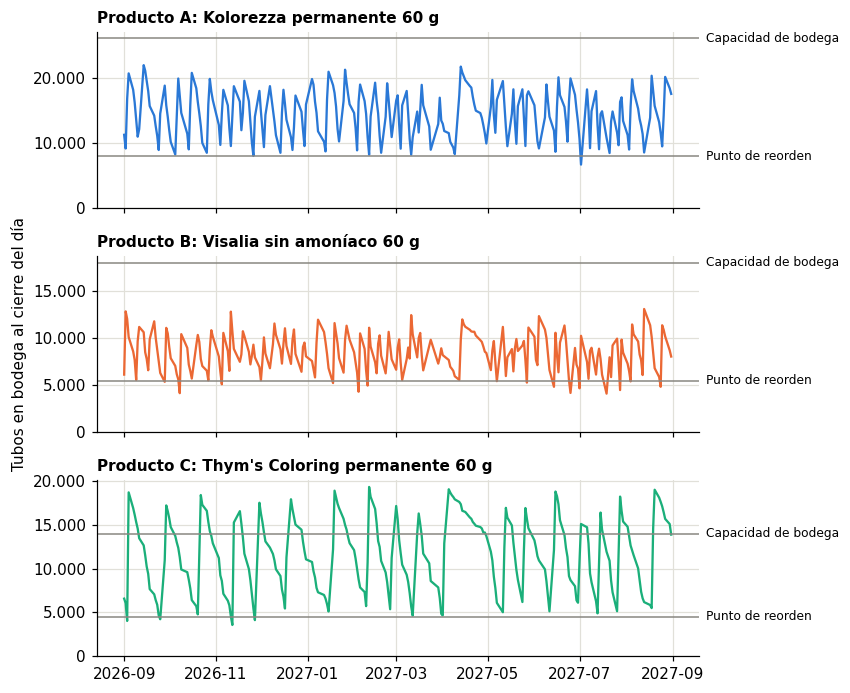

In [15]:
# Inventario de producto terminado, con el punto de reorden y la capacidad de bodega de cada producto
fig, axs = plt.subplots(3, 1, figsize=(9, 6.4), sharex=True)
for ax, p in zip(axs, PRODS):
    ax.plot(diario.fecha, diario[f"pt_{p}"], color=COLOR[p], linewidth=1.5)
    for valor, texto in ((prod.bodega[p], "Capacidad de bodega"), (prod.rop[p], "Punto de reorden")):
        ax.axhline(valor, color=COLOR["gris"], linewidth=1)
        ax.annotate(texto, (1, valor), xycoords=ax.get_yaxis_transform(), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=8, annotation_clip=False)
    ax.set_title(f"Producto {p}: {prod.nombre[p]}", fontsize=10); ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(lambda v, _: es(v))
axs[1].set_ylabel("Tubos en bodega al cierre del día")
fig.tight_layout(rect=(0, 0, 0.87, 1)); plt.show()

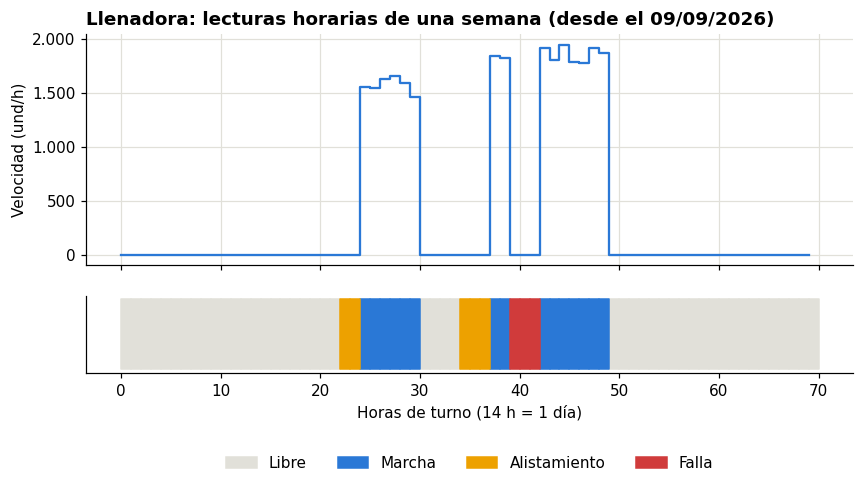

In [16]:
# Una semana de la llenadora vista por sus sensores (se busca una semana con falla, si la hay)
falla = tele.t_h[tele.llenadora_estado == "falla"]
t0 = max(0, int(falla.iloc[0] // base.H) - 2) * base.H if len(falla) else 10 * base.H
semana = tele[(tele.t_h >= t0) & (tele.t_h < t0 + 5 * base.H)].assign(h=lambda x: x.t_h - t0)
color_estado = {"libre": "#e1e0d9", "marcha": COLOR["A"], "alistamiento": "#eda100", "falla": "#d03b3b"}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 4), sharex=True, height_ratios=[3, 1])
ax1.step(semana.h, semana.llenadora_vel_und_h, where="post", color=COLOR["A"], linewidth=1.5)
ax1.set_ylabel("Velocidad (und/h)"); ax1.yaxis.set_major_formatter(lambda v, _: es(v))
ax1.set_title(f"Llenadora: lecturas horarias de una semana (desde el {semana.momento.iloc[0]:%d/%m/%Y})")
for estado, col in color_estado.items():
    ax2.broken_barh([(t, 1) for t in semana.h[semana.llenadora_estado == estado]], (0, 1), color=col, label=estado.capitalize())
ax2.set_yticks([]); ax2.grid(False); ax2.set_xlabel(f"Horas de turno ({es(base.H)} h = 1 día)")
ax2.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.9))
plt.show()

### 3.5 Métricas de eficiencia

Takt time, tiempo de ciclo, throughput y WIP medidos en el gemelo (promedio de las réplicas). Los
del Corte 1 están a escala de la zona y con jornada de 8 h, por eso no son comparables en magnitud.

In [17]:
rep_base = replicar()
kb = rep_base.mean()
horas_dia = par["turnos"] * par["horas_turno"]
proceso = {p: sum(horas_nominales_lote(e, p) for e in EQUIPOS) for p in PRODS}                 # h por lote, todas las estaciones
fabricacion = {p: sum(horas_nominales_lote(e, p) for e in (E_PES, E_MEZ, E_QC)) for p in PRODS}
display(pd.DataFrame({
    "Corte 1 (zona, 8 h/día)": ["41,5 s/und (0,69 min)", "86,7 und/h", "3,5 a 5,5 h (dato de la empresa)", "304 a 477 und"],
    "Libro (planta)": [f"{es(par['dias_mes']*horas_dia*3600/DEMANDA_PLANTA, 1)} s/und",
                       f"{es(DEMANDA_PLANTA/(par['dias_mes']*horas_dia))} und/h",
                       f"{es(min(proceso.values()), 1)} a {es(max(proceso.values()), 1)} h por lote",
                       f"{es(prod.wip.sum())} tubos"],
    "Gemelo (planta, 12 meses)": [f"{es(kb['takt_s_und'], 1)} s/und", f"{es(kb['throughput_und_h'])} und/h",
                                  f"{es(kb['flujo_lote_h'], 1)} h por lote", f"{es(kb['wip_prom_tubos'])} tubos"]},
    index=["Takt time", "Throughput", "Tiempo de ciclo (flujo)", "WIP promedio"]))
print(f"Pesaje + mezcla + control de calidad según el libro: {es(min(fabricacion.values()), 1)} a {es(max(fabricacion.values()), 1)} h por lote")

,"Corte 1 (zona, 8 h/día)",Libro (planta),"Gemelo (planta, 12 meses)"
Takt time,"41,5 s/und (0,69 min)","11,1 s/und","10,3 s/und"
Throughput,"86,7 und/h",325 und/h,352 und/h
Tiempo de ciclo (flujo),"3,5 a 5,5 h (dato de la empresa)","12,7 a 14,5 h por lote","16,9 h por lote"
WIP promedio,304 a 477 und,8.500 tubos,5.308 tubos


Pesaje + mezcla + control de calidad según el libro: 3,9 a 5,0 h por lote


### 3.6 Restricciones: capacidad, demanda y almacenamiento

In [18]:
semiancho = stats.t.ppf(0.975, N_REP - 1) * rep_base.std(ddof=1) / math.sqrt(N_REP)     # intervalo del 95 %
filas = [("Capacidad", "Ocupación de la llenadora (cuello de botella)", "ocup_llenadora_%", "%", 1),
         ("Capacidad", "Ocupación de los reactores", "ocup_mezcla_%", "%", 1),
         ("Capacidad", "Ocupación de la encartonadora", "ocup_encartonadora_%", "%", 1),
         ("Capacidad", "Ocupación del empaque", "ocup_empaque_%", "%", 1),
         ("Demanda", "Nivel de servicio (despacho inmediato)", "nivel_servicio_%", "%", 2),
         ("Demanda", "Mayor acumulado de pedidos pendientes", "pendiente_max_und", "tubos", 0),
         ("Almacenamiento", "Inventario total máximo", "pt_max_und", "tubos", 0),
         ("Almacenamiento", "Días con la bodega total sobre su capacidad", "dias_sobre_bodega_%", "%", 1),
         ("Almacenamiento", "Días con el producto C sobre su bodega", "dias_C_sobre_bodega_%", "%", 1),
         ("Materia prima", "Menor existencia de base y colorantes", "mp_min_kg", "kg", 0)]
display(pd.DataFrame([{"Tipo": tipo, "Indicador": texto, "Promedio": es(kb[col], d), "± (95 %)": es(semiancho[col], d), "Unidad": und}
                      for tipo, texto, col, und, d in filas]))
print(f"Bodega total: {es(prod.bodega.sum())} tubos | bodega de C: {es(prod.bodega['C'])} | punto de reorden + lote de C: {es(prod.rop['C'] + prod.lote['C'])}")
print(f"Réplicas en las que algún lote esperó materia prima: {(rep_base.espera_mp_h > 0).sum()} de {N_REP}")

,Tipo,Indicador,Promedio,± (95 %),Unidad
0,Capacidad,Ocupación de la llenadora (cuello de botella),"28,9","0,4",%
1,Capacidad,Ocupación de los reactores,"10,5","0,1",%
2,Capacidad,Ocupación de la encartonadora,"16,0","0,2",%
3,Capacidad,Ocupación del empaque,"15,4","0,2",%
4,Demanda,Nivel de servicio (despacho inmediato),"99,99","0,02",%
5,Demanda,Mayor acumulado de pedidos pendientes,0,0,tubos
6,Almacenamiento,Inventario total máximo,49.226,627,tubos
7,Almacenamiento,Días con la bodega total sobre su capacidad,"0,0","0,0",%
8,Almacenamiento,Días con el producto C sobre su bodega,"32,3","1,1",%
9,Materia prima,Menor existencia de base y colorantes,800,152,kg


Bodega total: 58.000 tubos | bodega de C: 14.000 | punto de reorden + lote de C: 20.100
Réplicas en las que algún lote esperó materia prima: 3 de 30


### 3.7 Escenarios

Todos se corren con las mismas semillas, así las diferencias se deben a la decisión y no al azar.

In [19]:
escenarios = {
    "Base: política del libro": {},
    "Sin estacionalidad (demanda plana)": dict(peso_estacional_real=0, peso_estacional_pron=0),
    "Punto de reorden ajustado con el pronóstico": dict(politica="rop_pronostico"),
    "Compras con pronóstico sin estacionalidad": dict(peso_estacional_pron=0),
    "Lote de C de 7.800 tubos": dict(lote={"C": 7800}),
    "Un solo turno": dict(turnos=1),
}
res = {nombre: (rep_base if not cfg else replicar(cfg)) for nombre, cfg in escenarios.items()}
cols = {"nivel_servicio_%": "Nivel de servicio (%)", "pt_prom_und": "Inventario promedio (tubos)",
        "dias_C_sobre_bodega_%": "Días C sobre su bodega (%)", "ocup_llenadora_%": "Ocupación llenadora (%)",
        "flujo_lote_h": "Flujo por lote (h)"}
comp = pd.DataFrame({nombre: df.mean()[list(cols)] for nombre, df in res.items()}).T.rename(columns=cols)
comp["Réplicas con faltante de materia prima"] = [int((df.espera_mp_h > 0).sum()) for df in res.values()]
tabla(comp, {"Nivel de servicio (%)": 2, "Días C sobre su bodega (%)": 1, "Ocupación llenadora (%)": 1, "Flujo por lote (h)": 1})

,Nivel de servicio (%),Inventario promedio (tubos),Días C sobre su bodega (%),Ocupación llenadora (%),Flujo por lote (h),Réplicas con faltante de materia prima
Base: política del libro,"99,99",34.697,"32,3","28,9","16,9",3
Sin estacionalidad (demanda plana),"100,00",34.724,"32,3","29,0","16,8",0
Punto de reorden ajustado con el pronóstico,"99,97",36.740,"36,9","28,7","17,1",1
Compras con pronóstico sin estacionalidad,"99,85",34.627,"32,1","28,9","16,9",6
Lote de C de 7.800 tubos,"99,96",31.108,"0,0","29,5","16,1",1
Un solo turno,"97,97",28.240,"19,9","57,5","18,3",1


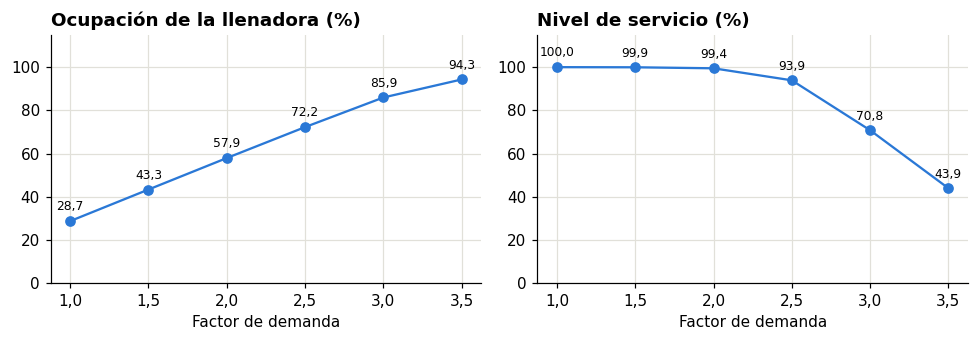

In [20]:
factores = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
estres = pd.DataFrame({f: replicar(dict(factor_demanda=f, politica="rop_pronostico", modelar_mp=False)).mean() for f in factores}).T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, titulo in ((ax1, "ocup_llenadora_%", "Ocupación de la llenadora (%)"), (ax2, "nivel_servicio_%", "Nivel de servicio (%)")):
    ax.plot(estres.index, estres[col], marker="o", color=COLOR["A"])
    for f, valor in estres[col].items():
        ax.annotate(es(valor, 1), (f, valor), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_title(titulo); ax.set_xlabel("Factor de demanda"); ax.set_ylim(0, 115)
    ax.xaxis.set_major_formatter(lambda v, _: es(v, 1))
fig.tight_layout(); plt.show()